In [1]:
import numpy as np
import matplotlib.pyplot as plt
import toolbox as funcs
import sim_funcs as sim
import os
import pickle
import scipy.io
import time

In [70]:
network_params = {"realizations": 200  #(200 originally) small scale realizations  (Critical : should be a large value if large number APs and UEs are used)
                    , "tau_c": 200 # total samples in coherence block
                    , "tau_p": 1  # samples for pilots
                    , "p_k": 200  # uplink max power (mW)
                    # , "uplink_variance_dbm": -94 # Receiver noise power (dBm)
                                     }

area_params = {"delta_h": 10 # height difference
                    , "area": 100  # lxl Service Area
                    , "bandwidth": 100e6
                    , "L": 4  # APs
                    , "N": 2  # antennas per AP
                    , "K": 3  # UEs
                    # , "uplink_variance_dbm": -94 # Receiver noise power (dBm)
                    , "carrier_frequency": 2000  # carrier frequency (MHz)
                    , "sigma_sf_los": 8  # Shadow fading LoS (dB)
                    , "AP_pos_rand": True
                                     }

sim_params = {"setups": 1000,
                     "batch":network_params["realizations"],
                     "v":-1,
                     "d": 0,   #rician factor (0: no LoS component)
                     "norm_type" : np.inf,
                     "tests" :10
                    }

In [71]:
# (R_block, B_block, HMean_block, kappa_block, UEpos_block, APpos_block) = sim.create_areas(area_params, sim_params["tests"])
area_block = sim.create_areas(area_params, sim_params["tests"])

test  1 / 10
test  2 / 10
test  3 / 10
test  4 / 10
test  5 / 10
test  6 / 10
test  7 / 10
test  8 / 10
test  9 / 10
test  10 / 10


In [24]:
# test_tau = [1,2,3,4,6,8,10,15,20]
test_tau = [1]
results = {}
for tau in test_tau:
    results[tau] = sim.run_test(network_params, area_params, sim_params, area_block, tau)

data = {
    "area_params" : area_params,
    "test_tau" : test_tau,
    "results" : results
}

L = area_params["L"]
N = area_params["N"]
K = area_params["K"]


# filename = f"Results/results_L{L}N{N}K{K}_rician5.pkl"

# with open(filename, "wb") as outfile:
#     pickle.dump(data, outfile)

number of inv Z interf. matrixes: 0


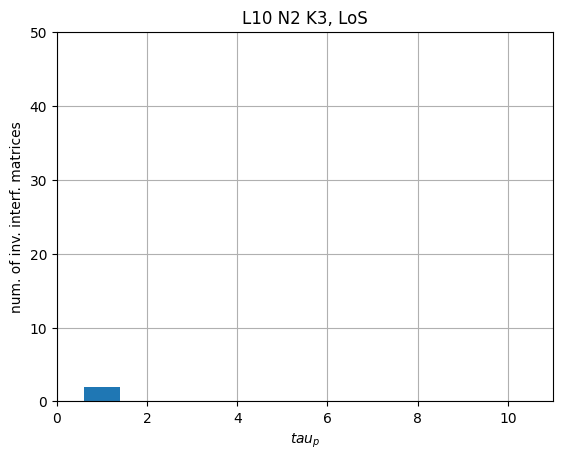

In [55]:
data = pickle.load(open("Results/results_L10N2K3_rician5.pkl", "rb"))
results = data["results"]

plt.bar(results.keys(), results.values())
plt.ylim(0, sim_params["tests"])
plt.xlim(0,11)
# plt.yticks(range(0, sim_params["tests"]+1, 1))
plt.xlabel("$tau_p$")
plt.ylabel("num. of inv. interf. matrices")
plt.title("L10 N2 K3, LoS")
plt.grid()
plt.show()
# plt.savefig("plots/L10N2K3_LoS.png")

In [79]:
i = 8

(R_block, B_block, HMean_block, kappa_block, UEpos_block, APpos_block) = area_block

R_spatial_corr_norm = R_block[i,:,:,:,:]
B_channel_gain =  B_block[i,:,:]
HMean_norm = HMean_block[i,:,:,:]
k_rician_factor = kappa_block[i,:,:]
UEpos = UEpos_block[i,:,:]
APpos = APpos_block[i,:,:]

area_values = (R_spatial_corr_norm, B_channel_gain, HMean_norm, k_rician_factor, UEpos, APpos)


M, u, b, C, sigma, SINR, UEpos, APpos, D_DCC = sim.run_sim(network_params, area_params, sim_params, area_values, i)

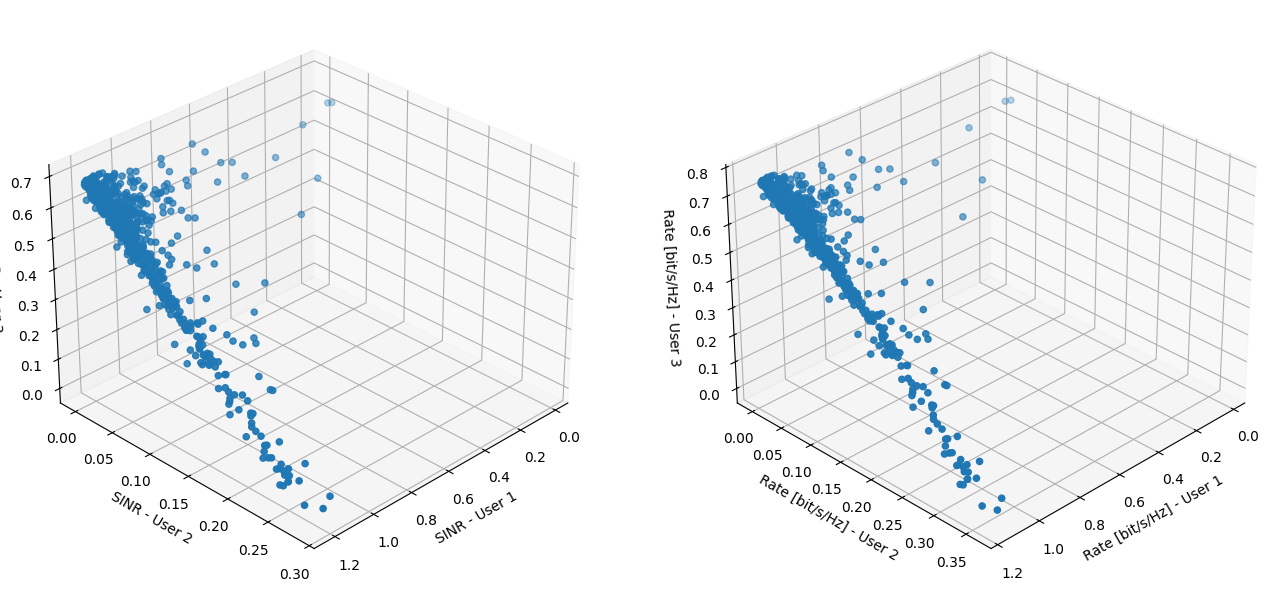

In [80]:
%matplotlib inline

x,y,z = SINR
rate_x = np.log2(1+np.array(x) )
rate_y = np.log2(1+np.array(y) )
rate_z = np.log2(1+np.array(z) )

# Create a figure with two 3D subplots
fig, (ax1, ax2) = plt.subplots(1, 2, subplot_kw={'projection': '3d'}, figsize=(14,6))
# fig = plt.figure()
# ax = fig.add_subplot(projection='3d')
ax1.scatter(x,y,z)

ax1.set_xlabel("SINR - User 1", fontsize=10)
ax1.set_ylabel("SINR - User 2", fontsize=10)
ax1.set_zlabel("SINR - User 3", fontsize=10)
ax1.view_init(elev=30, azim=45)  # Set elevation to 30° and azimuth to 45°

ax2.scatter(rate_x, rate_y, rate_z)

ax2.set_xlabel("Rate [bit/s/Hz] - User 1", fontsize=10)
ax2.set_ylabel("Rate [bit/s/Hz] - User 2", fontsize=10)
ax2.set_zlabel("Rate [bit/s/Hz] - User 3", fontsize=10)
ax2.view_init(elev=30, azim=45)  # Set elevation to 30° and azimuth to 45°

plt.tight_layout()
plt.show()

In [76]:
p_max = network_params["p_k"]
K = area_params["K"]

A = 1/p_max * np.eye(K)
M_k = np.zeros((K,K,K))
for k in range(K):
    M_k[k,:,:] = M + u @ A[:,k][:,np.newaxis].T
    print("inv Z?: ", funcs.is_invZ(M_k[k,:,:]), "\n")

inv Z?:  False 

inv Z?:  False 

inv Z?:  False 



(0.0, 100.0)

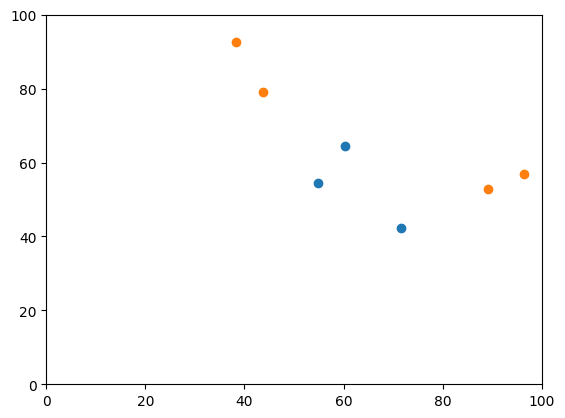

In [28]:
K = area_params["K"]

area = area_params["area"]
fig = plt.figure()
ax = fig.add_subplot()
ax.scatter(np.real(UEpos), np.imag(UEpos))
ax.scatter(np.real(APpos), np.imag(APpos))
ax.set_xlim(0, area)
ax.set_ylim(0, area)